# Trabajo de Herramientas básicas para el Análisis de Datos




### Planteo de caso y selección del data set


**Alerta temprana de reprobación estudiantil**

Las instituciones educativas enfrentan el desafío de identificar a los estudiantes en riesgo de fracaso escolar antes de las evaluaciones finales para poder intervenir a tiempo. Con una tasa general de aprobación estimada en el 77.4% dentro de los 100,000 registros del Student Exam Performance & Success Dataset, el conjunto de datos recopila información valiosa de rendimiento previo y antecedentes académicos (como previous_exam_score, previous_gpa y attendance_percentage). Esto permite analizar patrones y aislar las características que definen al segmento de alumnos con riesgo de reprobación (pass_status o calificación F).

- **Pregunta de análisis:**

¿Se puede predecir con precisión si un alumno va a reprobar el examen basándose únicamente en su asistencia y su rendimiento académico histórico?

- **Objetivos:**

1. Desarrollar un modelo predictivo de clasificación que permita identificar tempranamente a los estudiantes con alto riesgo de reprobación para el diseño de estrategias preventivas de apoyo escolar.
2. Analizar los distintos factores y variables (conocimientos previos, hábitos, entorno y bienestar) que influyen en el estado de aprobación final de los estudiantes.
```

# 1.Carga del dataset

### a.Importar libreria para carga y análisis de dataset



In [ ]:
import pandas as pd

### b.Importar datos

In [ ]:
estudiantesdata=pd.read_csv("/content/drive/MyDrive/Curso herramientas básicas de Análisis de Datos/student_exam_performance.csv")

In [ ]:
estudiantesdata

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,...,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,...,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,...,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,...,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,...,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,STU_099996,17,Male,Undergraduate,Public,Upper-Middle,NaN,Suburban,78.73,NaN,...,Medium,5,95,62,76.13,8.36,66.46,C,Pass,Medium
99996,STU_099997,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,...,Easy,24,94,91,84.29,8.68,96.54,A,Pass,High
99997,STU_099998,16,Female,High School,Public,Upper-Middle,High School,Suburban,84.69,3.27,...,Medium,24,85,65,62.32,9.97,74.66,C,Pass,Medium
99998,STU_099999,15,Female,High School,Private,High,Master,Rural,74.70,3.06,...,Medium,28,93,81,100.00,10.00,85.85,A,Pass,High


## 2.Análisis exploratorio

In [ ]:
# Describe nombres de las columnas
estudiantesdata.columns

Index(['student_id', 'age', 'gender', 'education_level', 'school_type',
       'family_income', 'parent_education', 'urban_rural',
       'previous_exam_score', 'previous_gpa', 'attendance_percentage',
       'assignment_completion_rate', 'class_participation',
       'study_hours_per_day', 'self_study_hours', 'private_tuition',
       'online_learning_hours', 'study_consistency', 'study_environment',
       'study_method', 'revision_frequency', 'practice_tests_completed',
       'notes_quality', 'sleep_hours', 'sleep_quality', 'daily_screen_time',
       'physical_activity_hours', 'break_frequency', 'stress_level',
       'motivation_level', 'internet_access', 'device_availability',
       'educational_app_usage', 'online_course_hours', 'exam_difficulty',
       'exam_preparation_days', 'questions_attempted', 'questions_correct',
       'time_management_score', 'exam_anxiety_level', 'exam_score',
       'performance_grade', 'pass_status', 'performance_level'],
      dtype='object')

### a.Diccionario de columnas

**Datos del estudiante**

- student_id (Identificador del estudiante): Código de
identificación único para cada alumno.

- age (Edad): Edad del estudiante en años.

gender (Género): Identidad de género autodeclarada.

- education_level (Nivel educativo): Etapa académica actual (Escuela secundaria / High School o Estudios universitarios / Undergraduate).

- school_type (Tipo de escuela): Tipo de institución educativa (Pública, Privada o Concertada/Charter).

- family_income (Ingresos familiares): Nivel socioeconómico de ingresos del hogar (Bajo a Alto).

- parent_education (Educación de los padres): Nivel educativo más alto alcanzado por alguno de los padres (desde secundaria hasta doctorado).

- urban_rural (Zona urbana/rural): Entorno geográfico de residencia del estudiante (Urbano, Suburbano, Rural).

  **Datos sobre Base académica**

- previous_exam_score (Puntaje de examen previo): Calificación porcentual histórica en exámenes anteriores (de 30 a 100).

- previous_gpa (Promedio de calificaciones previo): Promedio acumulado de calificaciones en una escala de 4.0.

- attendance_percentage (Porcentaje de asistencia): Porcentaje de clases a las que asistió el alumno.

- assignment_completion_rate (Tasa de finalización de tareas): Frecuencia o porcentaje con el que el alumno entrega sus deberes a tiempo.

- class_participation (Participación en clase): Nivel de intervención y participación activa del estudiante en el aula.

- private_tuition (Clases particulares / Tutoría privada):Indica si el estudiante recibe apoyo escolar o tutorías externas fuera de la escuela.

**Hábitos de Estudio y Comportamiento**

- study_hours_per_day (Horas de estudio por día): Cantidad de horas diarias dedicadas al estudio.

- self_study_hours (Horas de estudio independiente): Tiempo dedicado específicamente al autoestudio sin supervisión.

- study_consistency (Constancia en el estudio): Qué tan regular o disciplinado es el hábito de estudio a lo largo del tiempo.

- study_environment (Entorno de estudio): Calidad o tranquilidad del lugar donde el estudiante repasa (por ejemplo, si tiene un espacio adecuado).

- study_method (Método de estudio): Técnica o enfoque que utiliza para aprender (resúmenes, mapas conceptuales, repetición, etc.).

- revision_frequency (Frecuencia de repaso): Con qué regularidad repasa los temas aprendidos antes de los exámenes.

- practice_tests_completed (Pruebas de práctica completadas): Cantidad de exámenes de prueba o simulacros que ha realizado.

- notes_quality (Calidad de los apuntes): Nivel de prolijidad, completitud y utilidad de las notas que toma en clase.

** Estilo de Vida y Bienestar**

- sleep_hours (Horas de sueño): Promedio de horas que duerme el estudiante al día.

- sleep_quality (Calidad del sueño): Qué tan reparador y profundo es el descanso del alumno.

- daily_screen_time (Tiempo diario frente a pantallas): Cantidad de horas que pasa usando dispositivos electrónicos (móvil, PC, TV) en actividades de ocio.

- physical_activity_hours (Horas de actividad física): Tiempo dedicado a la semana a hacer deporte o ejercicio físico.

- break_frequency (Frecuencia de descansos): Con qué regularidad toma pausas durante sus jornadas de estudio.

- stress_level (Nivel de estrés): Grado de tensión o presión mental que experimenta el alumno.

- motivation_level (Nivel de motivación): Grado de entusiasmo e impulso interno por aprender y alcanzar metas académicas.

**Factores de Tecnología y Exámenes**

- internet_access (Acceso a internet): Disponibilidad de conexión a internet en el hogar o lugar de estudio (Sí/No).

- device_availability (Disponibilidad de dispositivos): Acceso a herramientas tecnológicas propias (ordenador, tablet) para estudiar.

- educational_app_usage (Uso de aplicaciones educativas): Frecuencia con la que utiliza plataformas o apps para potenciar su aprendizaje.

- online_course_hours (Horas de cursos en línea): Tiempo invertido en capacitaciones o clases virtuales externas.

- exam_difficulty (Dificultad del examen): Nivel de complejidad percibido de la prueba a evaluar.

- exam_preparation_days (Días de preparación para el examen): Con cuántos días de anticipación comienza a estudiar específicamente para el examen final.

- questions_attempted (Preguntas intentadas): Cantidad de preguntas que el estudiante llegó a responder en el examen.

- questions_correct (Preguntas correctas): Cantidad de aciertos obtenidos en el examen.

- time_management_score (Puntaje de gestión del tiempo): Indicador de qué tan bien administra su tiempo durante la prueba y su rutina diaria.

- exam_anxiety_level (Nivel de ansiedad ante los exámenes): Grado de nerviosismo o pánico que experimenta el estudiante frente a las evaluaciones.

**Variables Objetivo Calculadas / Diseñadas**
Estas son las variables principales que los modelos de Machine Learning intentan predecir:

- exam_score (Puntuación final del examen): Calificación final numérica continua (de 0 a 100). Ideal para tareas de regresión.

- pass_status (Estado de aprobación): Resultado binario que indica si el alumno Aprobó (mayor o igual a 50) o Reprobó (menos de 50). Ideal para clasificación binaria.

- performance_grade (Calificación de rendimiento): Notas en formato de letra estándar internacional (A, B, C, D, F) según una distribución académica realista.

- performance_level (Nivel de rendimiento): Categorización del desempeño general del alumno en tres niveles: Alto (High), Medio (Medium) o Bajo (Low).

### b.Entendimiento de datos

In [ ]:
#cantidad de filas y columnas
estudiantesdata.shape

(100000, 44)

In [ ]:
#primeras 5 filas de la tabla
estudiantesdata.head()

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,...,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,...,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,...,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,...,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,...,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low


In [ ]:
# información del dataset
estudiantesdata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 44 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   student_id                  100000 non-null  object 
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  object 
 3   education_level             100000 non-null  object 
 4   school_type                 100000 non-null  object 
 5   family_income               100000 non-null  object 
 6   parent_education            93474 non-null   object 
 7   urban_rural                 100000 non-null  object 
 8   previous_exam_score         100000 non-null  float64
 9   previous_gpa                92207 non-null   float64
 10  attendance_percentage       90137 non-null   float64
 11  assignment_completion_rate  100000 non-null  float64
 12  class_participation         100000 non-null  object 
 13  study_hours_per

### c.Exploración estadística inicial


In [ ]:
# Reviso valores estadísticos de la variable previous_exam_score
estudiantesdata["previous_exam_score"].describe()

,previous_exam_score
count,100000.000000
mean,69.531033
std,11.379108
min,30.000000
25%,61.820000
50%,69.530000
75%,77.232500
max,100.000000


## 3.Limpieza

### a.Identificación y eliminación de duplicados

In [ ]:
estudiantesdata.duplicated().sum()

np.int64(0)

Observación: No hay duplicados

### b.Identificación de valores nulos y criterio de tratamiento

In [ ]:
estudiantesdata.isnull().sum()

,0
student_id,0
age,0
gender,0
education_level,0
school_type,0
family_income,0
parent_education,6526
urban_rural,0
previous_exam_score,0
previous_gpa,7793


Se observa que, en todas las variables analizadas, el porcentaje de datos faltantes respecto del total de registros es inferior al 10%. Por lo tanto, se considera adecuado continuar con el análisis. Para esto, se imputan los valores faltantes de las variables numéricas que se utilizarán en etapas posteriores, reemplazandolos por la mediana de cada variable.

In [ ]:
estudiantesdata["time_management_score"] = estudiantesdata["time_management_score"].fillna(estudiantesdata["time_management_score"].median())
estudiantesdata['attendance_percentage'] = estudiantesdata['attendance_percentage'].fillna(estudiantesdata['attendance_percentage'].median())
estudiantesdata['previous_gpa'] = estudiantesdata['previous_gpa'].fillna(estudiantesdata['previous_gpa'].median())

In [ ]:
#Reviso que ya no haya faltantes en las variables que "rellené"
estudiantesdata.isnull().sum()

,0
student_id,0
age,0
gender,0
education_level,0
school_type,0
family_income,0
parent_education,6526
urban_rural,0
previous_exam_score,0
previous_gpa,0


## 4.Desarrollo de modelo predictivo de estudiantes "en riesgo"

### a.Identificación de alumnos en riesgo académico
Creamos una nueva columna condicional basada en el promedio de calificaciones (`previous_gpa` < 3), el puntaje de exámenes anteriores (`previous_exam_score` < 60) y el porcentaje de asistencia (`attendance_percentage` < 70).

In [ ]:
# Defino las condiciones lógicas para considerar un alumno "en riesgo de desaprobar"
condicion_riesgo = (
    (estudiantesdata['previous_gpa'] < 3.0) |
    (estudiantesdata['previous_exam_score'] < 70.0) |
    (estudiantesdata['attendance_percentage'] < 70.0)
)

# Creo la nueva columna booleana (True si cumple alguna de las tres, False de lo contrario)
estudiantesdata['alumnos_en_riesgo'] = condicion_riesgo

# Se imprime un resumen de cuántos estudiantes quedaron clasificados en riesgo
print("Cantidad de alumnos en riesgo:")
print(estudiantesdata['alumnos_en_riesgo'].value_counts())

# Visualizamos una muestra de los alumnos identificados en riesgo
display(estudiantesdata[estudiantesdata['alumnos_en_riesgo'] == True][['previous_gpa', 'previous_exam_score', 'attendance_percentage', 'alumnos_en_riesgo']].head())

Cantidad de alumnos en riesgo:
alumnos_en_riesgo
True     71231
False    28769
Name: count, dtype: int64


,previous_gpa,previous_exam_score,attendance_percentage,alumnos_en_riesgo
0,2.95,78.36,81.49,True
1,2.89,73.40,84.75,True
3,2.57,60.61,84.91,True
4,2.84,74.79,88.21,True
5,2.78,67.68,97.11,True


### b. Comparación de Alumnos en Riesgo vs Estado de Aprobación Real
Analizamos cuántas de nuestras alertas de riesgo coinciden con los estudiantes que efectivamente reprobaron el examen.

In [ ]:
# Cuento el total de alumnos que realmente reprobaron (pass_status == 'Fail')
total_reprobados = (estudiantesdata['pass_status'] == 'Fail').sum()

# Filtro los alumnos que están marcados en riesgo
alumnos_riesgo_df = estudiantesdata[estudiantesdata['alumnos_en_riesgo'] == True]

# Se cuenta cuántos de estos alumnos en riesgo efectivamente reprobaron ('Fail')
coincidencias_reprobados = (alumnos_riesgo_df['pass_status'] == 'Fail').sum()

# Calculo el porcentaje respecto al total de reprobados
porcentaje_coincidencia = (coincidencias_reprobados / total_reprobados) * 100 if total_reprobados > 0 else 0

# Se imprimen los resultados
print(f"Total de alumnos reales reprobados (Fail) en el dataset: {total_reprobados}")
print(f"Alumnos identificados en riesgo que efectivamente reprobaron: {coincidencias_reprobados}")
print(f"Porcentaje de coincidencias respecto al total de reprobados: {porcentaje_coincidencia:.2f}%")

Total de alumnos reales reprobados (Fail) en el dataset: 22611
Alumnos identificados en riesgo que efectivamente reprobaron: 20341
Porcentaje de coincidencias respecto al total de reprobados: 89.96%


Nos da un porcentaje de coincidencia de 89.96%. Parece un método efectivo para identificar alumnos en riesgo.

# 5.Visualización

### a. Importar librerías de visualización
Importamos `matplotlib.pyplot` y `seaborn` para dar inicio a la creación de los gráficos.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos un estilo visual agradable por defecto
sns.set_theme(style="whitegrid")

### Gráfico 1: Relación entre la Asistencia y el Estado de Aprobación
Este gráfico de cajas nos muestra la distribución de los porcentajes de asistencia comparando a los alumnos que aprobaron ('Pass') contra los que reprobaron ('Fail').

/tmp/ipykernel_2639/116604819.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=estudiantesdata, x='pass_status', y='attendance_percentage', palette='Set2')


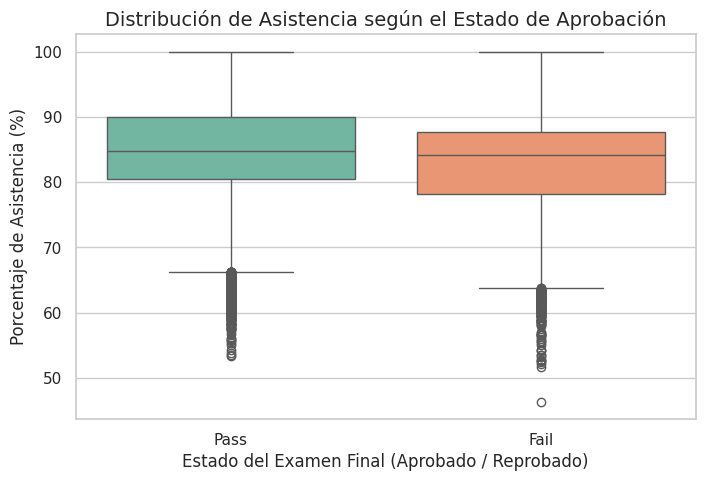

In [ ]:
plt.figure(figsize=(8, 5))

# Creamos el gráfico de cajas comparativo
sns.boxplot(data=estudiantesdata, x='pass_status', y='attendance_percentage', palette='Set2')

# Añadimos títulos y etiquetas claras
plt.title('Distribución de Asistencia según el Estado de Aprobación', fontsize=14)
plt.xlabel('Estado del Examen Final (Aprobado / Reprobado)', fontsize=12)
plt.ylabel('Porcentaje de Asistencia (%)', fontsize=12)

# Mostramos el gráfico
plt.show()

### Gráfico 2: Desempeño Histórico (GPA previo vs. Calificación de Examen Previo)
Este gráfico de dispersión nos ayuda a ver cómo se relacionan el promedio de calificaciones anterior con la nota de exámenes previos, y cómo se agrupan los que finalmente aprobaron o reprobaron. Para que sea rápido de graficar y entender, tomaremos una muestra pequeña y representativa de los datos.

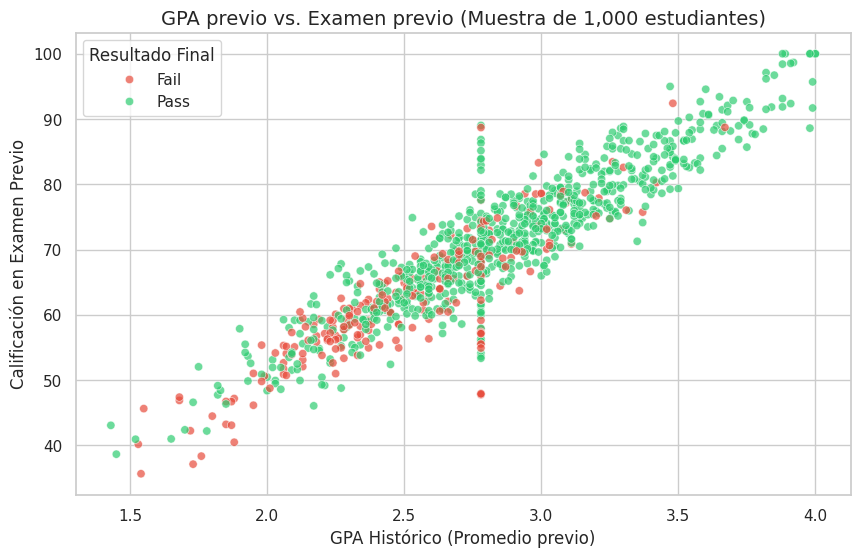

In [ ]:
# Tomamos una muestra aleatoria de 1000 estudiantes para no saturar el gráfico con tantos puntos
muestra_estudiantes = estudiantesdata.sample(n=1000, random_state=42)

plt.figure(figsize=(10, 6))

# Graficamos los puntos usando GPA en X, Examen previo en Y, y los pintamos según si aprobó o no
sns.scatterplot(
    data=muestra_estudiantes,
    x='previous_gpa',
    y='previous_exam_score',
    hue='pass_status',
    palette={'Pass': '#2ecc71', 'Fail': '#e74c3c'},
    alpha=0.7
)

# Añadimos títulos y leyendas
plt.title('GPA previo vs. Examen previo (Muestra de 1,000 estudiantes)', fontsize=14)
plt.xlabel('GPA Histórico (Promedio previo)', fontsize=12)
plt.ylabel('Calificación en Examen Previo', fontsize=12)
plt.legend(title='Resultado Final')

plt.show()

### Gráfico 3: Proporción de aprobados dentro de la alerta de Alumnos en Riesgo
Este gráfico de barras nos mostrará de qué manera nuestra clasificación de riesgo se asocia con el resultado final real.

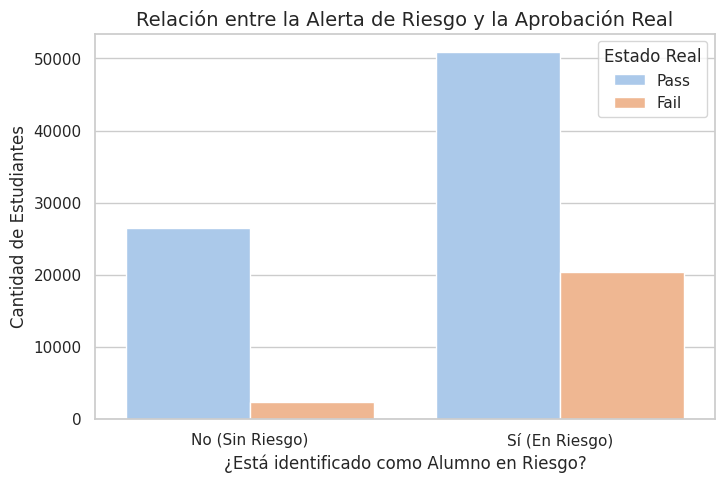

In [ ]:
plt.figure(figsize=(8, 5))

# Creamos un gráfico de barras contando las aprobaciones agrupadas por si están en riesgo o no
sns.countplot(
    data=estudiantesdata,
    x='alumnos_en_riesgo',
    hue='pass_status',
    palette='pastel'
)

# Configuramos etiquetas legibles
plt.title('Relación entre la Alerta de Riesgo y la Aprobación Real', fontsize=14)
plt.xlabel('¿Está identificado como Alumno en Riesgo?', fontsize=12)
plt.ylabel('Cantidad de Estudiantes', fontsize=12)
plt.xticks([0, 1], ['No (Sin Riesgo)', 'Sí (En Riesgo)'])
plt.legend(title='Estado Real')

plt.show()

### Descargar el dataset limpio y modificado
Con el siguiente bloque de código exportamos las modificaciones realizadas en el dataset a un archivo CSV y lo descargamos localmente para realizar presentación en Power BI

In [ ]:
from google.colab import files

# Guardamos el DataFrame modificado en un archivo CSV
nombre_archivo = 'student_exam_performance_limpio.csv'
estudiantesdata.to_csv(nombre_archivo, index=False)

# Descargamos el archivo a la computadora
files.download(nombre_archivo)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>